# 15. Diffusion with reaction

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 3 and 14

Most industrial catalysts are porous pellets a few millimetres across. The reactants must
diffuse into the pores to reach the active surface, and if the reaction is fast they are
used up before they get far: the inside of the pellet is wasted. The same competition
between diffusion and reaction decides how fast concrete loses its protection of the steel
inside it, how a drug spreads from an implant, and how a pollutant is absorbed into a
reacting liquid. Mathematically it is the fin of Chapter 3 again: heat conducted along a
fin and lost from its sides becomes a reactant diffusing into a pellet and consumed in it.

This chapter answers two engineering questions. The first is the size of catalyst pellets
for a fixed-bed converter: small pellets use their catalyst fully but cost pressure drop;
large pellets are cheap to blow through but mostly idle. Where is the balance? The second
is the carbonation of concrete in the buildings of Astana: carbon dioxide from the air
diffuses into the concrete and reacts with it, and once the reacted layer reaches the
reinforcing steel, the steel can corrode. How long does a given concrete cover last? The
checks solve the pellet equations by finite differences and by collocation, and the
carbonation front with a finite reaction rate.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import diffusion, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import diffusion, properties, reference
from engtransport.numerics import bisect
from engtransport.plotting import panel_label, use_style

use_style()
YEAR = 365.25 * 86400.0

## 15.1 Reaction in a porous pellet

Let a reactant of concentration $c$ diffuse into a porous pellet with effective diffusivity
$D_{eff}$ and react there at a rate $kc$ per unit pellet volume (first order). In steady
state, what diffuses into a small volume is consumed in it:

$$
D_{eff}\nabla^2 c = k c , \qquad c = c_s \ \text{at the surface} .
\tag{15.1}
$$

For a slab of half-thickness $L$, with $x$ measured from the mid-plane and $u = c/c_s$,
this is $u'' = \Phi^2 u$ with $\Phi = L\sqrt{k/D_{eff}}$, the *Thiele modulus* (Thiele 1939);
with $u'(0) = 0$ and $u(1) = 1$,

$$
u = \frac{\cosh(\Phi x/L)}{\cosh\Phi} ,
\tag{15.2}
$$

the profile of a fin with an insulated tip. The square of the modulus compares the rate of
reaction with the rate of diffusion across the pellet. The *effectiveness factor* is the
actual rate of the pellet over the rate it would have if the whole of it were at the
surface concentration; in steady state the actual rate is the flux through the surface,

$$
\eta = \frac{A\,D_{eff}\,(\partial c/\partial n)_s}{V k c_s} .
\tag{15.3}
$$

For the slab, $\eta = \tanh\Phi/\Phi$, the fin efficiency of Chapter 3 under another name.
At small $\Phi$ the pellet is used fully; at large $\Phi$ only a skin of thickness
$\sqrt{D_{eff}/k}$ reacts, and $\eta \to 1/\Phi$.

## 15.2 Shapes and orders

For other shapes Aris (1957) proposed to measure the pellet by its volume-to-surface ratio
$V/A$: the half-thickness $L$ of a slab, $R/2$ for a long cylinder and $R/3$ for a sphere.
With

$$
\phi = \frac{V}{A}\sqrt{\frac{k}{D_{eff}}} ,
\tag{15.4}
$$

the effectiveness factors of the three shapes are

$$
\eta_{slab} = \frac{\tanh\phi}{\phi}, \qquad
\eta_{cyl} = \frac{I_1(2\phi)}{\phi\,I_0(2\phi)}, \qquad
\eta_{sph} = \frac{1}{\phi}\left[\frac{1}{\tanh 3\phi} - \frac{1}{3\phi}\right] ,
\tag{15.5}
$$

with $I_0$ and $I_1$ modified Bessel functions (`diffusion.effectiveness_first_order`). All
three start at 1 and end at $1/\phi$, because at large $\phi$ only a thin skin reacts, and
a thin skin does not know the shape of what it covers; in between they differ by up to
14 %. For a reaction of order $n$, rate $kc^n$, the same asymptotic argument
gives a different factor, and Bischoff (1965) showed that the *generalized modulus*

$$
\phi_G = \frac{V}{A}\sqrt{\frac{n + 1}{2}\,\frac{k c_s^{\,n-1}}{D_{eff}}}
\tag{15.6}
$$

brings all orders onto the first-order curve at large and small moduli. In the laboratory
$k$ and $D_{eff}$ are often unknown, but the observed rate per pellet volume,
$r_{obs} = \eta k c_s$, is measured. Weisz and Prater (1954) combined it into a modulus that
contains only observables,

$$
\Phi_{WP} = \frac{r_{obs}(V/A)^2}{D_{eff}c_s} = \eta\phi^2 ,
\tag{15.7}
$$

and diffusion inside the pellets is negligible when $\Phi_{WP} \ll 1$ and controls the rate
when $\Phi_{WP} \gg 1$.

In [2]:
for phi in (0.2, 1.0, 3.0, 10.0):
    print(f"phi = {phi:5.1f}: eta slab {diffusion.effectiveness_first_order(phi, 'slab'):.4f}, "
          f"cylinder {diffusion.effectiveness_first_order(phi, 'cylinder'):.4f}, sphere {diffusion.effectiveness_first_order(phi, 'sphere'):.4f};"
          f" Weisz-Prater modulus {phi**2 * diffusion.effectiveness_first_order(phi, 'sphere'):.3f}")
phis = np.geomspace(0.02, 50, 300)
spread = np.max(np.abs(diffusion.effectiveness_first_order(phis, "sphere") / diffusion.effectiveness_first_order(phis, "slab") - 1))
print(f"largest difference between sphere and slab at the same phi: {100 * spread:.1f} %")

phi =   0.2: eta slab 0.9869, cylinder 0.9805, sphere 0.9768; Weisz-Prater modulus 0.039
phi =   1.0: eta slab 0.7616, cylinder 0.6978, sphere 0.6716; Weisz-Prater modulus 0.672
phi =   3.0: eta slab 0.3317, cylinder 0.3041, sphere 0.2963; Weisz-Prater modulus 2.667
phi =  10.0: eta slab 0.1000, cylinder 0.0975, sphere 0.0967; Weisz-Prater modulus 9.667
largest difference between sphere and slab at the same phi: 14.1 %


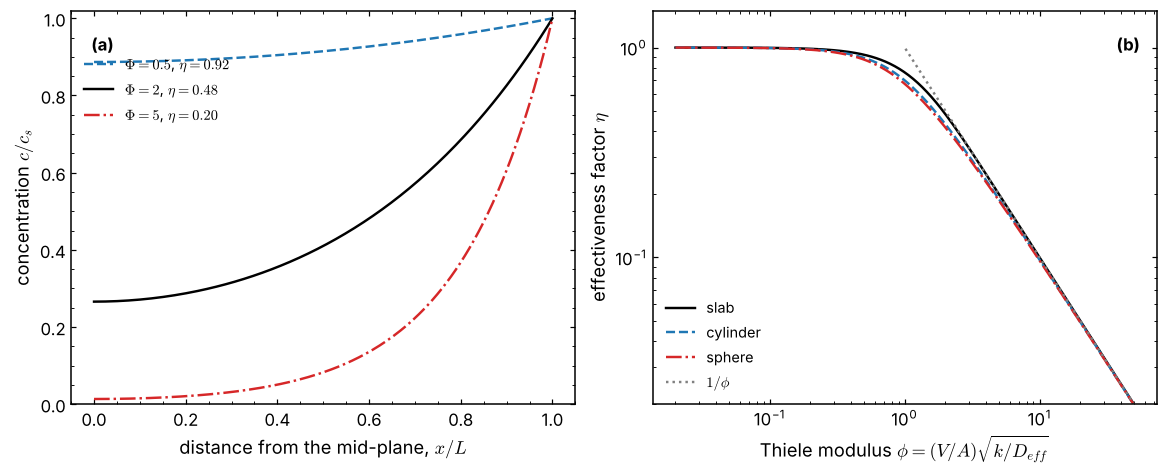

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
xg = np.linspace(0, 1, 200)
for Phi, style in ((0.5, "C0--"), (2.0, "k-"), (5.0, "C3-.")):
    ax1.plot(xg, np.cosh(Phi * xg) / np.cosh(Phi), style, label=fr"$\Phi = {Phi:g}$, $\eta = {math.tanh(Phi) / Phi:.2f}$")
ax1.set_xlabel(r"distance from the mid-plane, $x/L$")
ax1.set_ylabel(r"concentration $c/c_s$")
ax1.set_ylim(0, 1.02)
ax1.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92))
panel_label(ax1, "(a)", x=0.04, y=0.94)

for shape, style in (("slab", "k-"), ("cylinder", "C0--"), ("sphere", "C3-.")):
    ax2.loglog(phis, diffusion.effectiveness_first_order(phis, shape), style, label=shape)
ax2.loglog(phis[phis > 1], 1 / phis[phis > 1], ":", color="0.5", label=r"$1/\phi$")
ax2.set_xlabel(r"Thiele modulus $\phi = (V/A)\sqrt{k/D_{eff}}$")
ax2.set_ylabel(r"effectiveness factor $\eta$")
ax2.set_ylim(0.02, 1.5)
ax2.legend(loc="lower left")
panel_label(ax2, "(b)", x=0.92, y=0.94)
plt.show()

**Figure 15.1.** (a) Concentration across a slab pellet for three Thiele moduli,
Eq. (15.2). (b) Effectiveness factors of slab, cylinder and sphere against the modulus
based on $V/A$, Eqs. (15.4)–(15.5).

At $\Phi = 5$ the reactant hardly reaches the middle of the pellet, and only a fifth of its
catalyst works. Measured by $V/A$, the three shapes fall on nearly one curve: the sphere
differs from the slab by at most 14 %, near $\phi = 1$, and much less at both ends. This is
why one formula, with the right length, serves for pellets of any shape to within the
accuracy of the rate constant.

## 15.3 How large should the pellets be?

A fixed-bed converter is a tube filled with pellets through which the gas flows. Take a
gas-phase reaction that is first order in its reactant, carried out at 450 °C in a bed of
spherical pellets with void fraction $\varepsilon = 0.4$. The rate constant per pellet
volume is $k = 10$ s⁻¹ and the effective diffusivity in the pellets $D_{eff} = 2$ mm²/s
(both assumed typical values); the gas, with the properties of air, flows through the bed
at a superficial velocity $u = 0.5$ m/s, and 95 % of the reactant must be converted. In
plug flow the reactant falls as $u\,dc/dz = -(1 - \varepsilon)\eta k c$, so the bed must be

$$
L_{bed} = \frac{u\,\ln[1/(1 - X)]}{(1 - \varepsilon)\,\eta k}
\tag{15.8}
$$

long, inversely proportional to $\eta$. The pressure drop follows from Ergun's (1952)
correlation for packed beds,

$$
\frac{\Delta p}{L_{bed}} = 150\frac{\mu u(1 - \varepsilon)^2}{\varepsilon^3 d_p^2}
+ 1.75\frac{\rho u^2(1 - \varepsilon)}{\varepsilon^3 d_p} ,
\tag{15.9}
$$

with a viscous term that grows as $1/d_p^2$ and an inertial one as $1/d_p$. Smaller pellets
shorten the bed but raise the pressure drop per metre faster than they shorten the bed.

In [4]:
k_v, D_eff, u_s, eps_b, X = 10.0, 2e-6, 0.5, 0.4, 0.95
gas = properties.dry_air_properties(723.15)


def converter(d_p):
    phi = d_p / 6 * math.sqrt(k_v / D_eff)                          # V/A = d_p/6 for a sphere
    eta = diffusion.effectiveness_first_order(phi, "sphere")
    L = u_s * math.log(1 / (1 - X)) / ((1 - eps_b) * eta * k_v)     # Eq. (15.8)
    dpdz = (150 * gas["mu"] * u_s * (1 - eps_b) ** 2 / (eps_b**3 * d_p**2)
            + 1.75 * gas["rho"] * u_s**2 * (1 - eps_b) / (eps_b**3 * d_p))   # Eq. (15.9)
    return {"phi": phi, "eta": eta, "L": L, "dp": dpdz * L}


print(f"gas at 450 C: mu = {gas['mu'] * 1e6:.1f} uPa s, rho = {gas['rho']:.3f} kg/m3")
for d_p in (0.0015, 0.003, 0.006, 0.010):
    c = converter(d_p)
    print(f"pellets {1e3 * d_p:4.1f} mm: phi {c['phi']:.2f}, eta {c['eta']:.3f}, bed {c['L']:.3f} m, pressure drop {c['dp'] / 1e3:.2f} kPa")
L_kin = u_s * math.log(1 / (1 - X)) / ((1 - eps_b) * k_v)
print(f"bed with no diffusion limit (eta = 1): {L_kin:.3f} m")
d_budget = bisect(lambda d: converter(d)["dp"] - 1000.0, 0.001, 0.01)[0]
print(f"smallest pellet for a pressure drop of 1 kPa: {1e3 * d_budget:.2f} mm")

gas at 450 C: mu = 34.9 uPa s, rho = 0.488 kg/m3
pellets  1.5 mm: phi 0.56, eta 0.852, bed 0.293 m, pressure drop 2.31 kPa
pellets  3.0 mm: phi 1.12, eta 0.630, bed 0.396 m, pressure drop 0.91 kPa
pellets  6.0 mm: phi 2.24, eta 0.381, bed 0.656 m, pressure drop 0.49 kPa
pellets 10.0 mm: phi 3.73, eta 0.244, bed 1.022 m, pressure drop 0.36 kPa
bed with no diffusion limit (eta = 1): 0.250 m
smallest pellet for a pressure drop of 1 kPa: 2.77 mm


With 6 mm pellets only 38 % of the catalyst works and the bed is 0.66 m long, with a
pressure drop of 0.49 kPa. Halving the pellets raises $\eta$ to 0.63 and shortens the bed
by 40 %, but nearly doubles the pressure drop; at 1.5 mm the bed is close to its kinetic
limit of 0.25 m and the pressure drop is 2.3 kPa. A blower budget of 1 kPa allows pellets
down to 2.8 mm. The best size thus comes from the price of catalyst against the price of
pumping, and the Thiele modulus is what links the two. Industrial catalysts with a strong
diffusion limit are therefore often made as rings or with the active metal only in a thin
outer shell (Exercise 2), which give a small $V/A$ without a small pellet.

## 15.4 Concrete carbonation

The pore water of fresh concrete is strongly alkaline, and this protects the steel bars
inside from corrosion. Carbon dioxide from the air diffuses into the pores and reacts with
the calcium hydroxide and calcium silicate hydrate, which lowers the alkalinity. The
reaction is fast compared with diffusion, so it happens in a thin front: behind it the
concrete is carbonated, ahead of it untouched (Papadakis, Vayenas and Fardis 1991). If the
front moves slowly, the carbon dioxide crosses the carbonated layer of depth $x$ in steady
state, with flux $D_{eff}c_0/x$, and is consumed at the front by $a$ moles of reacting
material per unit volume of concrete:

$$
a\frac{dx}{dt} = \frac{D_{eff}c_0}{x} \quad\Rightarrow\quad x = \sqrt{\frac{2D_{eff}c_0\,t}{a}} ,
\tag{15.10}
$$

the *shrinking-core* law, the Stefan tube of Chapter 14 in another guise. Take air with
420 ppm of CO₂ ($c_0 = 0.0175$ mol/m³ at 20 °C), a carbonated layer with
$D_{eff} = 10^{-8}$ m²/s, and $a = 1500$ mol/m³ of carbonatable material (both assumed
values for an ordinary concrete in moderately dry air).

In [5]:
c0, D_c, a_c = 41.6 * 420e-6, 1e-8, 1500.0
for years in (10, 50, 100):
    print(f"after {years:3d} years: carbonation depth {1e3 * diffusion.shrinking_core_depth(years * YEAR, D_c, c0, a_c):.1f} mm")
for cover in (0.015, 0.025, 0.040):
    t_c = cover**2 * a_c / (2 * D_c * c0) / YEAR
    print(f"cover {1e3 * cover:.0f} mm reached after {t_c:5.0f} years (at 1000 ppm indoors: {t_c * 420 / 1000:5.0f} years)")

after  10 years: carbonation depth 8.6 mm
after  50 years: carbonation depth 19.2 mm
after 100 years: carbonation depth 27.1 mm
cover 15 mm reached after    31 years (at 1000 ppm indoors:    13 years)
cover 25 mm reached after    85 years (at 1000 ppm indoors:    36 years)
cover 40 mm reached after   218 years (at 1000 ppm indoors:    91 years)


The front advances 9 mm in the first ten years and only 19 mm more in the next ninety. A
cover of 25 mm is reached after 85 years, and since the time grows as the square of the
cover, 15 mm lasts only 31 years and 40 mm over two centuries. Indoors, where the air holds
over twice as much carbon dioxide, every time is divided by 2.4; but indoors the concrete is
dry, and steel corrodes only where water reaches it. The square-root law is also why
standards specify cover thickness rather than a coating: doubling the cover quadruples the
life.

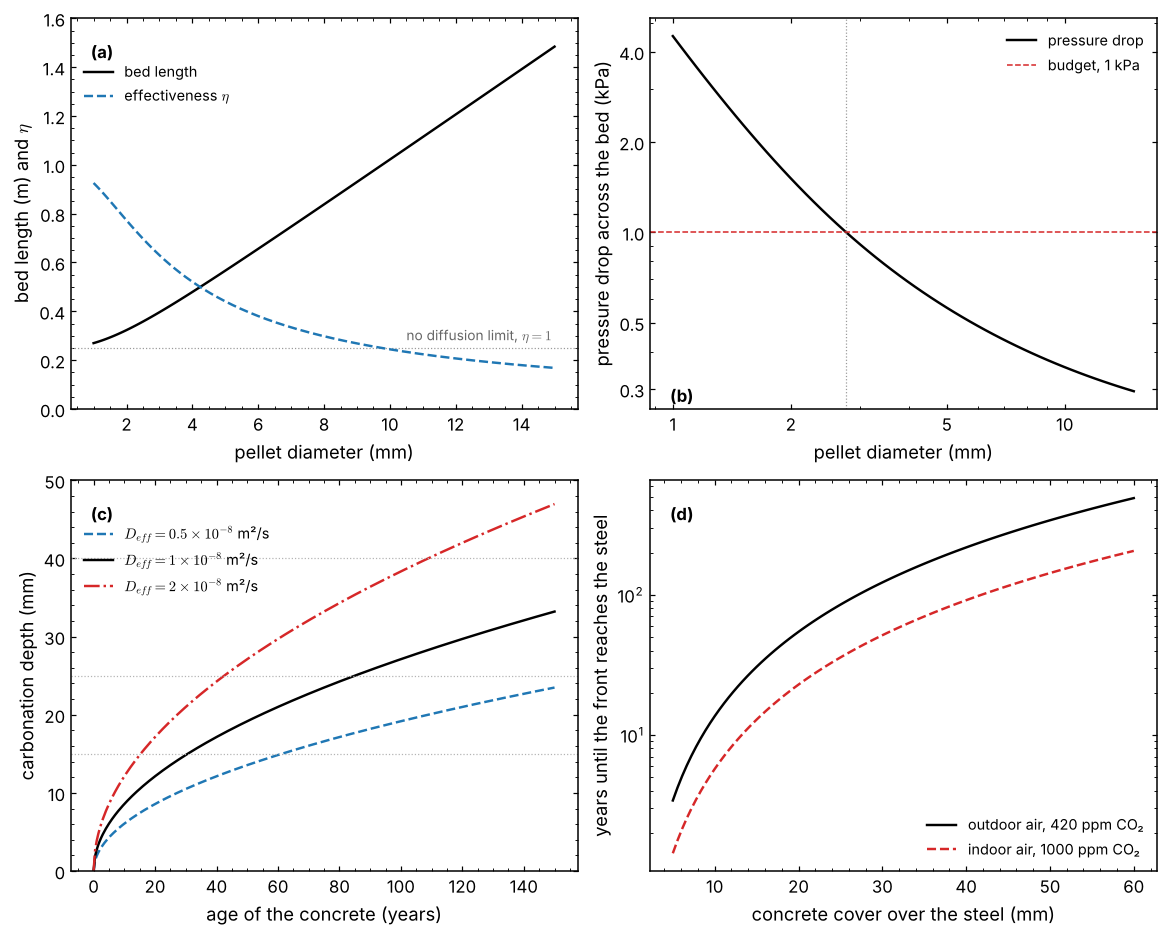

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

d_grid = np.geomspace(0.001, 0.015, 60)
conv = [converter(d) for d in d_grid]
ax1.plot(1e3 * d_grid, [c["L"] for c in conv], "k-", label="bed length")
ax1.axhline(L_kin, color="0.6", ls=":", lw=0.8)
ax1.text(10.5, L_kin + 0.03, r"no diffusion limit, $\eta = 1$", color="0.4", fontsize=9)
ax1.plot(1e3 * d_grid, [c["eta"] for c in conv], "C0--", label=r"effectiveness $\eta$")
ax1.set_xlabel("pellet diameter (mm)")
ax1.set_ylabel(r"bed length (m) and $\eta$")
ax1.set_ylim(0, 1.6)
ax1.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92))
panel_label(ax1, "(a)", x=0.04, y=0.94)

ax2.loglog(1e3 * d_grid, [c["dp"] / 1e3 for c in conv], "k-", label="pressure drop")
ax2.axhline(1.0, color="C3", ls="--", lw=1.0, label="budget, 1 kPa")
ax2.axvline(1e3 * d_budget, color="0.6", ls=":", lw=0.8)
ax2.set_xticks([1, 2, 5, 10])
ax2.set_yticks([0.3, 0.5, 1, 2, 4])
for axis in (ax2.xaxis, ax2.yaxis):
    axis.set_major_formatter(plt.ScalarFormatter())
    axis.set_minor_formatter(plt.NullFormatter())
ax2.set_xlabel("pellet diameter (mm)")
ax2.set_ylabel("pressure drop across the bed (kPa)")
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

years = np.linspace(0, 150, 300)
for D, style in ((0.5e-8, "C0--"), (1e-8, "k-"), (2e-8, "C3-.")):
    ax3.plot(years, 1e3 * diffusion.shrinking_core_depth(years * YEAR, D, c0, a_c), style,
             label=fr"$D_{{eff}} = {D * 1e8:g}\times10^{{-8}}$ m²/s")
for cover in (15, 25, 40):
    ax3.axhline(cover, color="0.7", lw=0.8, ls=":")
ax3.set_xlabel("age of the concrete (years)")
ax3.set_ylabel("carbonation depth (mm)")
ax3.set_ylim(0, 50)
ax3.legend(loc="upper left", bbox_to_anchor=(0.0, 0.92))
panel_label(ax3, "(c)", x=0.04, y=0.94)

covers = np.linspace(5, 60, 100)
for ppm, style, label in ((420, "k-", "outdoor air, 420 ppm CO₂"), (1000, "C3--", "indoor air, 1000 ppm CO₂")):
    ax4.semilogy(covers, (covers / 1e3) ** 2 * a_c / (2 * D_c * 41.6 * ppm * 1e-6) / YEAR, style, label=label)
ax4.set_xlabel("concrete cover over the steel (mm)")
ax4.set_ylabel("years until the front reaches the steel")
ax4.legend(loc="lower right")
panel_label(ax4, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 15.2.** (a) Length of a fixed-bed converter, Eq. (15.8), and the effectiveness of
its pellets against pellet diameter. (b) Pressure drop of the same bed, Eq. (15.9), with a
budget of 1 kPa. (c) Carbonation depth of concrete against age for three effective
diffusivities, Eq. (15.10), with three common covers. (d) Time for the front to reach the
steel against cover, outdoors and indoors.

Below 2 mm the bed length in (a) hardly changes, because the pellets are already used
fully, while the pressure drop in (b) keeps rising as $1/d_p^2$. In (c) a concrete with
twice the diffusivity, from a higher water–cement ratio or less curing, carbonates
$\sqrt{2}$ times as deep at every age. In (d) the time grows as the square of the cover:
every extra 10 mm counts more than the last, and indoor air shifts the whole curve down by
the same factor.

## 15.5 Checks

**Finite differences.** Equation (15.1) for slabs, cylinders and spheres, with any order
$n$, is solved by conservative finite differences on $N$ cells and Newton's method
(`diffusion.pellet_fd`), and its effectiveness factor compared with Eq. (15.5) for $n = 1$.

**Collocation.** For orders 1 and 2 the same problems are solved by `scipy.integrate.solve_bvp`
(`reference.pellet_bvp`), and the effectiveness against $\phi_G$ is compared with the
first-order curve, to see how well Bischoff's modulus (15.6) collapses the orders.

**A front of finite thickness.** Equation (15.10) assumes an infinitely fast reaction and
neglects the carbon dioxide stored in the pores of the carbonated layer. Both can be put
back. With porosity $\varepsilon$, a reacting material of concentration $s$ and a reaction
of finite rate $kcs$,

$$
\varepsilon\frac{\partial c}{\partial t} = D_{eff}\frac{\partial^2 c}{\partial x^2} - kcs ,
\qquad \frac{\partial s}{\partial t} = -kcs ,
\tag{15.11}
$$

which `reference.reacting_front_march` solves by the method of lines. For a fast reaction
the front has a sharp limit with storage, a one-phase Stefan problem like the freezing
front of Chapter 6:

$$
x_f = 2\lambda\sqrt{D_{eff}t/\varepsilon} , \qquad \lambda e^{\lambda^2}\operatorname{erf}\lambda = \frac{St}{\sqrt{\pi}} ,
\qquad St = \frac{\varepsilon c_0}{a} ,
\tag{15.12}
$$

which reduces to Eq. (15.10) as $St \to 0$ (`reference.one_phase_front_exact`). In concrete
$St$ is about $2\times10^{-6}$; the march uses $St = 0.1$ so that the storage term can be
seen, and a sequence of reaction rates to show the approach to the sharp limit.

In [7]:
n_cells = np.array([20, 40, 80, 160, 320])
fd_err = {}
for shape in ("slab", "cylinder", "sphere"):
    exact = diffusion.effectiveness_first_order(2.0, shape)
    fd_err[shape] = np.array([abs(diffusion.pellet_fd(2.0, shape, 1.0, n)["eta"] / exact - 1) for n in n_cells])
    print(f"{shape:8s}: finite differences at phi = 2, relative error " + " ".join(f"{e:.1e}" for e in fd_err[shape]))
for shape in ("slab", "sphere"):
    for order in (1.0, 2.0):
        b = reference.pellet_bvp(2.0, shape, order)
        f = diffusion.pellet_fd(2.0, shape, order, 640)
        print(f"{shape:6s}, order {order:g}: collocation {b['eta']:.6f}, finite differences {f['eta']:.6f}")

phiG = np.geomspace(0.05, 20, 25)
collapse = {}
for shape in ("slab", "sphere"):
    for order in (0.5, 1.0, 2.0):
        if shape == "sphere" and order == 0.5:
            continue
        phi_raw = phiG / math.sqrt((order + 1) / 2)
        collapse[(shape, order)] = np.array([diffusion.pellet_fd(p, shape, order, 400)["eta"] for p in phi_raw])
        dev = collapse[(shape, order)] / diffusion.effectiveness_first_order(phiG, shape) - 1
        print(f"{shape:6s}, order {order:g}: eta against phi_G deviates from the first-order curve by {100 * dev.min():+.1f} to {100 * dev.max():+.1f} %")

St = 0.1
lam = reference.one_phase_front_exact(St)
print(f"St = {St}: lambda = {lam:.6f}; shrinking core (15.10) gives {math.sqrt(St / 2):.6f}")
print(f"concrete, St = {0.15 * c0 / a_c:.1e}: lambda / shrinking-core value - 1 = {reference.one_phase_front_exact(0.15 * c0 / a_c) / math.sqrt(0.15 * c0 / a_c / 2) - 1:.1e}")
t_ev = np.linspace(0.05, 2.0, 40)
fronts = {}
for Da in (1e2, 1e3, 1e4):
    sol = reference.reacting_front_march(Da, St, x_max=1.0, t_end=2.0, n=400, t_eval=t_ev)
    s_field = sol.y[400:]
    xf = []
    for k in range(len(sol.t)):
        sk = s_field[:, k]
        i = int(np.argmax(sk > 0.5))
        xf.append(np.interp(0.5, [sk[i - 1], sk[i]], [sol.x[i - 1], sol.x[i]]))
    fronts[Da] = np.array(xf)
    if Da == 1e4:
        prof_c, prof_s = sol.y[:400, -1], s_field[:, -1]
    lag = 2 * lam * np.sqrt(t_ev) - fronts[Da]
    print(f"Da = {Da:.0e}: front at t = 2 is {fronts[Da][-1]:.4f}; sharp limit {2 * lam * math.sqrt(2.0):.4f}"
          f" ({100 * (fronts[Da][-1] / (2 * lam * math.sqrt(2.0)) - 1):+.2f} %); lag at t = 0.5, 1, 2: "
          + ", ".join(f"{lag[np.argmin(abs(t_ev - tt))]:.4f}" for tt in (0.5, 1.0, 2.0)) + f"; 1/sqrt(Da) = {Da**-0.5:.4f}")

slab    : finite differences at phi = 2, relative error 1.2e-03 3.0e-04 7.4e-05 1.9e-05 4.6e-06
cylinder: finite differences at phi = 2, relative error 4.3e-03 1.1e-03 2.7e-04 6.8e-05 1.7e-05
sphere  : finite differences at phi = 2, relative error 9.4e-03 2.4e-03 5.9e-04 1.5e-04 3.7e-05


slab  , order 1: collocation 0.482014, finite differences 0.482014
slab  , order 2: collocation 0.390008, finite differences 0.390008
sphere, order 1: collocation 0.416673, finite differences 0.416677
sphere, order 2: collocation 0.343370, finite differences 0.343376


slab  , order 0.5: eta against phi_G deviates from the first-order curve by +0.0 to +6.4 %
slab  , order 1: eta against phi_G deviates from the first-order curve by +0.0 to +0.0 %


slab  , order 2: eta against phi_G deviates from the first-order curve by -5.0 to +0.0 %
sphere, order 1: eta against phi_G deviates from the first-order curve by +0.0 to +0.3 %
sphere, order 2: eta against phi_G deviates from the first-order curve by -4.3 to +0.0 %
St = 0.1: lambda = 0.220016; shrinking core (15.10) gives 0.223607
concrete, St = 1.7e-06: lambda / shrinking-core value - 1 = -2.9e-07
Da = 1e+02: front at t = 2 is 0.5892; sharp limit 0.6223 (-5.32 %); lag at t = 0.5, 1, 2: 0.0513, 0.0405, 0.0331; 1/sqrt(Da) = 0.1000


Da = 1e+03: front at t = 2 is 0.6155; sharp limit 0.6223 (-1.09 %); lag at t = 0.5, 1, 2: 0.0085, 0.0075, 0.0068; 1/sqrt(Da) = 0.0316


Da = 1e+04: front at t = 2 is 0.6205; sharp limit 0.6223 (-0.29 %); lag at t = 0.5, 1, 2: 0.0019, 0.0018, 0.0018; 1/sqrt(Da) = 0.0100


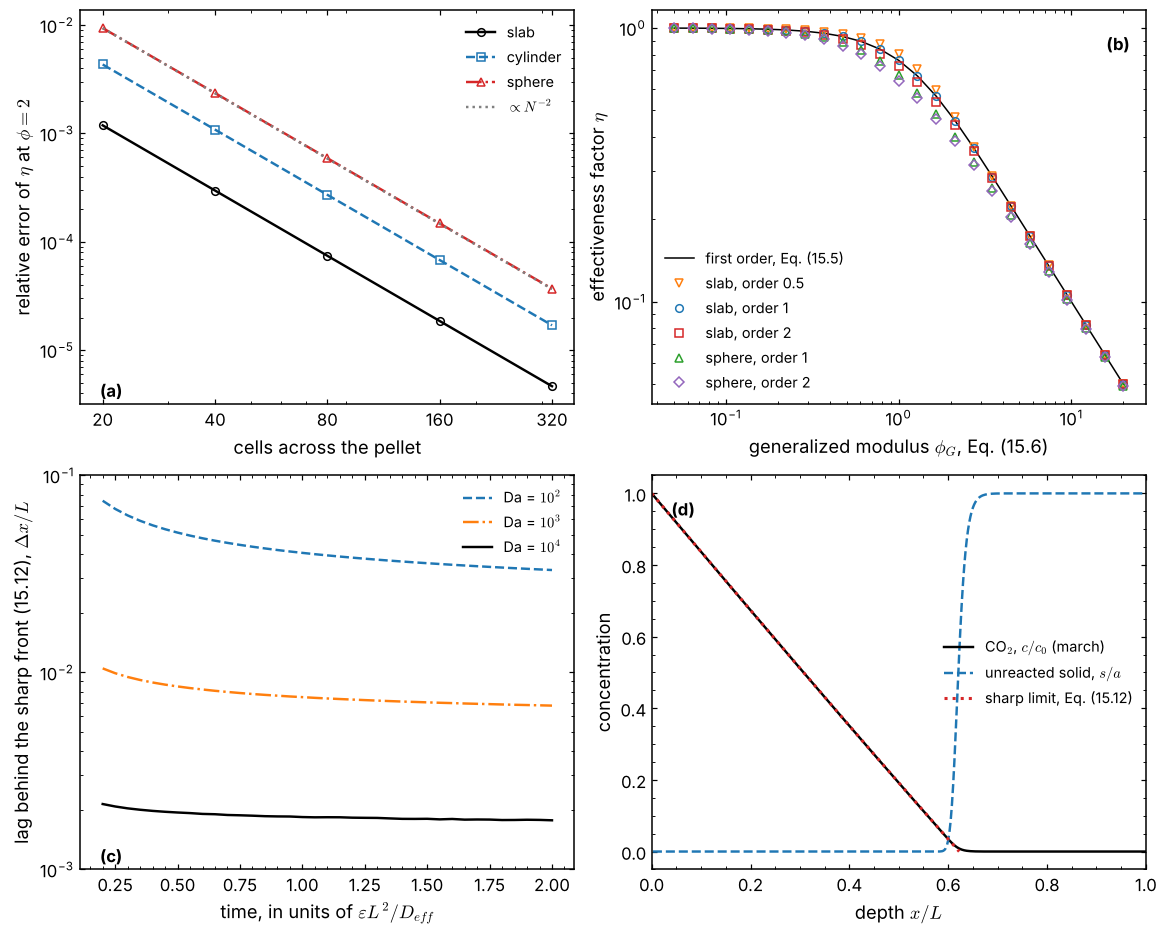

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes

for shape, style in (("slab", "ko-"), ("cylinder", "C0s--"), ("sphere", "C3^-.")):
    ax1.loglog(n_cells, fd_err[shape], style, ms=5, mfc="none", label=shape)
ax1.loglog(n_cells, fd_err["sphere"][0] * (n_cells[0] / n_cells) ** 2, ":", color="0.5", label=r"$\propto N^{-2}$")
ax1.set_xticks(n_cells)
ax1.xaxis.set_major_formatter(plt.ScalarFormatter())
ax1.xaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_xlabel("cells across the pellet")
ax1.set_ylabel(r"relative error of $\eta$ at $\phi = 2$")
ax1.legend(loc="upper right")
panel_label(ax1, "(a)", x=0.04, y=0.06)

ax2.loglog(phiG, diffusion.effectiveness_first_order(phiG, "slab"), "k-", lw=1.0, label="first order, Eq. (15.5)")
for (shape, order), style in zip(collapse, ("C1v", "C0o", "C3s", "C2^", "C4D")):
    ax2.loglog(phiG, collapse[(shape, order)], style, ms=5, mfc="none", label=f"{shape}, order {order:g}")
ax2.set_xlabel(r"generalized modulus $\phi_G$, Eq. (15.6)")
ax2.set_ylabel(r"effectiveness factor $\eta$")
ax2.legend(loc="lower left")
panel_label(ax2, "(b)", x=0.92, y=0.94)

late = t_ev >= 0.2
for Da, style in ((1e2, "C0--"), (1e3, "C1-."), (1e4, "k-")):
    ax3.semilogy(t_ev[late], 2 * lam * np.sqrt(t_ev[late]) - fronts[Da][late], style, label=fr"Da = $10^{{{int(math.log10(Da))}}}$")
ax3.set_xlabel(r"time, in units of $\varepsilon L^2/D_{eff}$")
ax3.set_ylabel(r"lag behind the sharp front (15.12), $\Delta x/L$")
ax3.set_ylim(1e-3, 0.1)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.06)

xe = np.linspace(0, 2 * lam * math.sqrt(2.0), 200)
ax4.plot(sol.x, prof_c, "k-", label=r"CO$_2$, $c/c_0$ (march)")
ax4.plot(sol.x, prof_s, "C0--", label=r"unreacted solid, $s/a$")
ax4.plot(xe, 1 - np.array([math.erf(v) for v in xe / (2 * math.sqrt(2.0))]) / math.erf(lam), "C3:", lw=2,
         label="sharp limit, Eq. (15.12)")
ax4.set_xlabel(r"depth $x/L$")
ax4.set_ylabel("concentration")
ax4.set_xlim(0, 1)
ax4.legend(loc="center right")
panel_label(ax4, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 15.3.** Checks. (a) Error of the finite-difference effectiveness factor against
Eq. (15.5). (b) Effectiveness factors of orders 0.5, 1 and 2 by finite differences against
the generalized modulus (15.6), with the first-order curve. (c) Lag of the front of a gas reacting
with a porous solid at three rates, Eq. (15.11), behind the sharp limit (15.12), for
$St = 0.1$. (d) Profiles of gas and unreacted solid at $t = 2$ for $Da = 10^4$, with the
sharp-limit profile.

The finite differences converge at second order for all three shapes, and agree with
collocation to $10^{-5}$ for orders 1 and 2. Bischoff's modulus gathers the orders at both
ends, but in between they spread by up to about 6 %: a half-order reaction is used more
fully, a second-order one less, than the first-order curve says. The finite-rate front lags
the sharp limit by a distance that does not grow with time and shrinks as the reaction gets
faster: for $Da = 10^4$ it settles at $0.0018L$, about a fifth of the reaction-zone scale
$\sqrt{D_{eff}/ka} = L/\sqrt{Da}$. Its relative effect fades as the front moves deeper, and
is 0.3 % at $t = 2$. For concrete, $St \approx 10^{-6}$ and the shrinking-core
formula (15.10) differs from the exact sharp front by $10^{-7}$.

## 15.6 What to trust

* *Kinetics and diffusivities* are the weak inputs. Rate constants come from experiments on
  crushed catalyst, effective diffusivities from porosity and tortuosity, and both are
  uncertain by tens of per cent. The Weisz–Prater modulus (15.7) at least says, from
  observables, whether diffusion matters.
* *Heat.* Exothermic reactions heat the pellet's interior, which can raise the rate and even
  make $\eta$ exceed one; the pellet then needs an energy balance as well.
* *External transfer.* The gas film around each pellet adds a resistance (Chapter 16) that
  this chapter leaves out.
* *Carbonation* depends strongly on humidity: in dry concrete the reaction needs water, in
  wet concrete the pores are blocked for gas. The $\sqrt{t}$ law describes the average
  behaviour; cracks carbonate much faster, and corrosion needs both carbonation and water.

## Summary

* Reaction inside a porous pellet obeys Eq. (15.1); the Thiele modulus compares reaction
  with diffusion, and the effectiveness factor (15.3) is the fraction of the catalyst at
  work: $\tanh\phi/\phi$ for a slab, the efficiency of a fin.
* Measured by $V/A$, Eq. (15.4), all shapes share nearly one curve (15.5), which falls as
  $1/\phi$ at large moduli. Bischoff's modulus (15.6) extends it to other orders, and the
  Weisz–Prater modulus (15.7) tests for diffusion limits from observables.
* Pellet size trades catalyst use against pressure drop, Eqs. (15.8)–(15.9): a 1 kPa budget
  sets 2.8 mm pellets in the converter of Section 15.3.
* A fast reaction moves as a sharp front, $x \propto \sqrt{t}$, Eq. (15.10): with assumed
  typical properties a 25 mm concrete cover carbonates in 85 years and a 40 mm cover in
  over 200.

## Exercises

Sample solutions are in [`solutions/part4_mass_transfer/15_solutions.ipynb`](../../solutions/part4_mass_transfer/15_solutions.ipynb).

1. **A diagnosis from two measurements.** In a laboratory reactor, spherical pellets 6 mm
   across convert a reactant at $c_s = 1$ mol/m³ at 4.0 mol/(m³ s) per pellet volume;
   the same catalyst crushed to 0.3 mm gives 9.5 mol/(m³ s). Assuming a first-order
   reaction, find the effectiveness factor of the pellets, the rate constant and the
   effective diffusivity. What is the Weisz–Prater modulus of each size?
2. **An egg-shell catalyst.** The converter of Section 15.3 uses 6 mm pellets. Instead of
   spreading the active metal through the pellet, the manufacturer puts the same amount in
   an outer shell 0.5 mm thick (so that the shell is more active per volume). Using
   `diffusion.pellet_fd` with an activity profile, find the effectiveness factor and the
   new bed length. If the support can hold at most ten times the uniform loading of metal
   per volume, what shell thickness gives the shortest bed?
3. **Starting up a pellet.** When the reactant is first admitted to the converter of
   Section 15.3, the 6 mm pellets fill from their surface. Treat a pellet as a sphere with a
   pore volume fraction of 0.5, so that $0.5\,\partial c/\partial t = D_{eff}\nabla^2 c - kc$,
   empty at $t = 0$ and at $c_s$ on its surface afterwards. How long does its reaction rate
   take to come within 1 % of the steady value? Compare a numerical solution with the
   slowest decay rate of the deviation, $(k + D_{eff}\pi^2/R^2)/0.5$, and say what the
   answer means for treating pellets as quasi-steady.
4. **A coating on the concrete.** A protective coating 0.3 mm thick with a CO₂ diffusivity
   of $10^{-11}$ m²/s (an assumed value) is applied to new concrete. How much longer does
   the front of Section 15.4 take to reach 25 mm? And if the coating is applied only after
   20 years? (Use `diffusion.shrinking_core_depth` with the coating as a resistance in
   series.)

## Suggested references

* E. W. Thiele, "Relation between catalytic activity and size of particle", *Ind. Eng.
  Chem.* **31**, 916 (1939).
* R. Aris, "On shape factors for irregular particles—I. The steady state problem.
  Diffusion and reaction", *Chem. Eng. Sci.* **6**, 262 (1957).
* K. B. Bischoff, "Effectiveness factors for general reaction rate forms", *AIChE J.*
  **11**, 351 (1965).
* P. B. Weisz and C. D. Prater, "Interpretation of measurements in experimental catalysis",
  *Adv. Catal.* **6**, 143 (1954).
* S. Ergun, "Fluid flow through packed columns", *Chem. Eng. Prog.* **48**(2), 89 (1952).
* V. G. Papadakis, C. G. Vayenas and M. N. Fardis, "Fundamental modeling and experimental
  investigation of concrete carbonation", *ACI Mater. J.* **88**, 363 (1991).
* E. L. Cussler, *Diffusion: Mass Transfer in Fluid Systems*, 3rd ed. (Cambridge
  University Press, 2009).

---

**Previous:** [14. Molecular diffusion](14_molecular_diffusion.ipynb) &nbsp;·&nbsp; **Next:** [16. Convective mass transfer](16_convective_mass_transfer.ipynb)